In [47]:
import pandas as pd
import numpy as np
import sklearn, xgboost
print("Ready", pd.__version__, sklearn.__version__, xgboost.__version__)

Ready 3.1.1 1.9.1 3.4.1


In [48]:
import pandas as pd
train = pd.read_csv("../data/UNSW_NB15_training-set.csv")
test  = pd.read_csv("../data/UNSW_NB15_testing-set.csv")
print(train.shape, test.shape)

(82332, 45) (175341, 45)


In [49]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  str    
 3   service            82332 non-null  str    
 4   state              82332 non-null  str    
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64  
 16  sinpkt             82332 non-null

In [50]:
print("Missing:", train.isnull().sum().sum())
print("Duplicates:", train.duplicated().sum())

Missing: 0
Duplicates: 0


In [51]:
print(train["label"].value_counts(normalize=True))
print(train["attack_cat"].value_counts())

label
1    0.5506
0    0.4494
Name: proportion, dtype: float64
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


In [52]:
train.select_dtypes(include="object").nunique()

C:\Users\hp\AppData\Local\Temp\ipykernel_25616\523624438.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.select_dtypes(include="object").nunique()


proto         131
service        13
state           7
attack_cat     10
dtype: int64

In [53]:
train.describe().T.head(20)

,count,mean,std,min,25%,50%,75%,max
id,82332.0,4.116650e+04,2.376735e+04,1.0,20583.750000,4.116650e+04,6.174925e+04,8.233200e+04
dur,82332.0,1.006756e+00,4.710444e+00,0.0,0.000008,1.413800e-02,7.193603e-01,5.999999e+01
spkts,82332.0,1.866647e+01,1.339164e+02,1.0,2.000000,6.000000e+00,1.200000e+01,1.064600e+04
dpkts,82332.0,1.754594e+01,1.155741e+02,0.0,0.000000,2.000000e+00,1.000000e+01,1.101800e+04
sbytes,82332.0,7.993908e+03,1.716423e+05,24.0,114.000000,5.340000e+02,1.280000e+03,1.435577e+07
dbytes,82332.0,1.323379e+04,1.514715e+05,0.0,0.000000,1.780000e+02,9.560000e+02,1.465753e+07
rate,82332.0,8.241089e+04,1.486204e+05,0.0,28.606114,2.650177e+03,1.111111e+05,1.000000e+06
sttl,82332.0,1.809677e+02,1.015134e+02,0.0,62.000000,2.540000e+02,2.540000e+02,2.550000e+02
dttl,82332.0,9.571300e+01,1.166677e+02,0.0,0.000000,2.900000e+01,2.520000e+02,2.530000e+02
sload,82332.0,6.454902e+07,1.798618e+08,0.0,11202.466797,5.770032e+05,6.514286e+07,5.268000e+09


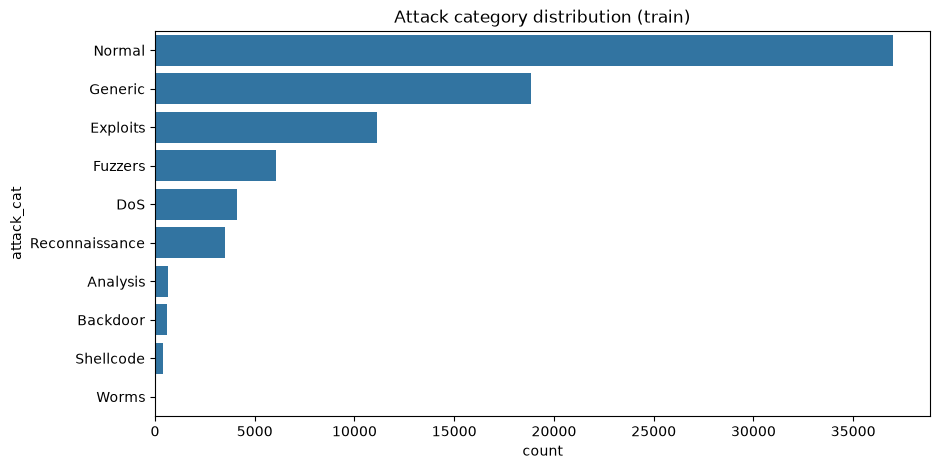

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5))
sns.countplot(data=train, y="attack_cat", order=train["attack_cat"].value_counts().index)
plt.title("Attack category distribution (train)")
plt.show()

In [55]:
print("Missing:", train.isnull().sum().sum())
print("Duplicates:", train.duplicated().sum())

Missing: 0
Duplicates: 0


In [56]:
train.select_dtypes(include="object").nunique()

C:\Users\hp\AppData\Local\Temp\ipykernel_25616\523624438.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.select_dtypes(include="object").nunique()


proto         131
service        13
state           7
attack_cat     10
dtype: int64

In [57]:
print(train["label"].value_counts(normalize=True))
print(test["label"].value_counts(normalize=True))

label
1    0.5506
0    0.4494
Name: proportion, dtype: float64
label
1    0.680622
0    0.319378
Name: proportion, dtype: float64


In [58]:
print("Missing:", train.isnull().sum().sum())
print("Duplicates:", train.drop(columns="id").duplicated().sum())
train.select_dtypes(include="object").nunique()

Missing:

C:\Users\hp\AppData\Local\Temp\ipykernel_25616\4025764074.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.select_dtypes(include="object").nunique()


 0
Duplicates: 26387


proto         131
service        13
state           7
attack_cat     10
dtype: int64

In [59]:
TARGETS = ["label", "attack_cat"]
DROP = ["id"] + TARGETS

X = train.drop(columns=DROP)
y_bin = train["label"]
y_multi = train["attack_cat"]

X_test = test.drop(columns=DROP)
y_test_bin = test["label"]
y_test_multi = test["attack_cat"]

print(X.shape, X_test.shape)

(82332, 42) (175341, 42)


In [60]:
from sklearn.model_selection import train_test_split

X_tr, X_val, ytr_bin, yval_bin, ytr_multi, yval_multi = train_test_split(
    X, y_bin, y_multi,
    test_size=0.2, stratify=y_multi, random_state=42
)
print(X_tr.shape, X_val.shape)

(65865, 42) (16467, 42)


In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

cat_cols = ["proto", "service", "state"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

In [62]:
Xtr_p  = preprocessor.fit_transform(X_tr)
Xval_p = preprocessor.transform(X_val)
print(Xtr_p.shape, Xval_p.shape)

(65865, 190) (16467, 190)


In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

clf = LogisticRegression(max_iter=1000)
clf.fit(Xtr_p, ytr_bin)
print(classification_report(yval_bin, clf.predict(Xval_p)))

              precision    recall  f1-score   support

           0       0.90      0.91      0.91      7400
           1       0.93      0.92      0.92      9067

    accuracy                           0.92     16467
   macro avg       0.92      0.92      0.92     16467
weighted avg       0.92      0.92      0.92     16467



In [64]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import time

def evaluate_binary(model, Xv, yv):
    t = time.time()
    pred = model.predict(Xv)
    ms = (time.time() - t) / len(Xv) * 1000
    tn, fp, fn, tp = confusion_matrix(yv, pred).ravel()
    print(classification_report(yv, pred, digits=3))
    print("FPR:", round(fp / (fp + tn), 4), "| FNR:", round(fn / (fn + tp), 4))
    print("ROC-AUC:", round(roc_auc_score(yv, model.predict_proba(Xv)[:, 1]), 4))
    print("Inference ms/sample:", round(ms, 5))

In [65]:
def evaluate_binary(model, Xv, yv):
    t = time.time()
    pred = model.predict(Xv)
    ms = (time.time() - t) / Xv.shape[0] * 1000
    tn, fp, fn, tp = confusion_matrix(yv, pred).ravel()
    print(classification_report(yv, pred, digits=3))
    print("FPR:", round(fp / (fp + tn), 4), "| FNR:", round(fn / (fn + tp), 4))
    print("ROC-AUC:", round(roc_auc_score(yv, model.predict_proba(Xv)[:, 1]), 4))
    print("Inference ms/sample:", round(ms, 5))

In [66]:
print("=== Random Forest ==="); evaluate_binary(rf, Xval_p, yval_bin)

=== Random Forest ===
              precision    recall  f1-score   support

           0      0.969     0.981     0.975      7400
           1      0.984     0.974     0.979      9067

    accuracy                          0.977     16467
   macro avg      0.976     0.977     0.977     16467
weighted avg      0.977     0.977     0.977     16467

FPR: 0.0193 | FNR: 0.0257
ROC-AUC: 0.9972
Inference ms/sample: 0.00906


In [67]:
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    n_jobs=-1, random_state=42, eval_metric="logloss")
xgb.fit(Xtr_p, ytr_bin)
print("=== XGBoost ==="); evaluate_binary(xgb, Xval_p, yval_bin)

=== XGBoost ===
              precision    recall  f1-score   support

           0      0.969     0.984     0.977      7400
           1      0.987     0.975     0.981      9067

    accuracy                          0.979     16467
   macro avg      0.978     0.979     0.979     16467
weighted avg      0.979     0.979     0.979     16467

FPR: 0.0155 | FNR: 0.0255
ROC-AUC: 0.9976
Inference ms/sample: 0.00111


In [68]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder().fit(ytr_multi)
ytr_m, yval_m = le.transform(ytr_multi), le.transform(yval_multi)

xgb_m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                      n_jobs=-1, random_state=42, eval_metric="mlogloss")
xgb_m.fit(Xtr_p, ytr_m)
print(classification_report(yval_m, xgb_m.predict(Xval_p), target_names=le.classes_, digits=3))

                precision    recall  f1-score   support

      Analysis      0.833     0.074     0.136       135
      Backdoor      0.429     0.026     0.048       117
           DoS      0.448     0.548     0.493       818
      Exploits      0.712     0.717     0.714      2227
       Fuzzers      0.709     0.713     0.711      1212
       Generic      0.993     0.979     0.986      3774
        Normal      0.963     0.988     0.975      7400
Reconnaissance      0.921     0.795     0.853       699
     Shellcode      0.582     0.513     0.545        76
         Worms      0.667     0.667     0.667         9

      accuracy                          0.882     16467
     macro avg      0.726     0.602     0.613     16467
  weighted avg      0.883     0.882     0.878     16467



In [69]:
from sklearn.utils.class_weight import compute_sample_weight

w = compute_sample_weight("balanced", ytr_m)

xgb_w = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                      n_jobs=-1, random_state=42, eval_metric="mlogloss")
xgb_w.fit(Xtr_p, ytr_m, sample_weight=w)

pred = xgb_w.predict(Xval_p)
print(classification_report(yval_m, pred, target_names=le.classes_, digits=3))

                precision    recall  f1-score   support

      Analysis      0.057     0.111     0.076       135
      Backdoor      0.075     0.325     0.122       117
           DoS      0.429     0.620     0.507       818
      Exploits      0.848     0.612     0.711      2227
       Fuzzers      0.748     0.721     0.734      1212
       Generic      0.996     0.976     0.986      3774
        Normal      0.982     0.954     0.968      7400
Reconnaissance      0.841     0.845     0.843       699
     Shellcode      0.407     0.724     0.521        76
         Worms      0.727     0.889     0.800         9

      accuracy                          0.862     16467
     macro avg      0.611     0.678     0.627     16467
  weighted avg      0.899     0.862     0.876     16467



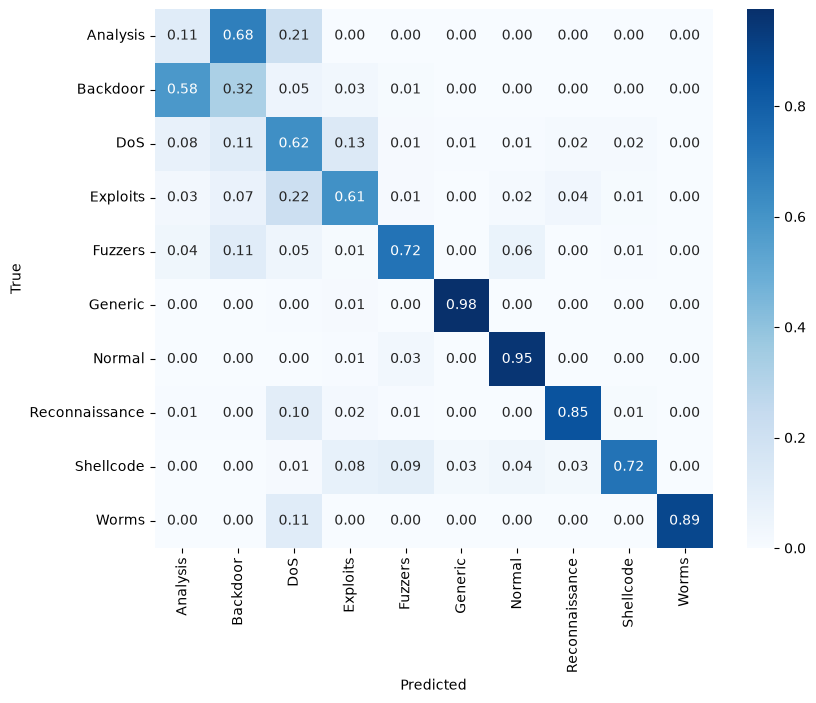

In [70]:
import seaborn as sns, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yval_m, pred, normalize="true")
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.ylabel("True"); plt.xlabel("Predicted"); plt.show()

In [71]:
from sklearn.metrics import f1_score
import numpy as np

print("Macro F1:", round(f1_score(yval_m, pred, average="macro"), 3))

normal_id = list(le.classes_).index("Normal")
true_atk = yval_m != normal_id
pred_atk = pred != normal_id
fpr = ((~true_atk) & pred_atk).sum() / (~true_atk).sum()
fnr = (true_atk & (~pred_atk)).sum() / true_atk.sum()
print("Binary FPR:", round(fpr, 4), "| Binary FNR:", round(fnr, 4))

Macro F1: 0.627
Binary FPR: 0.0455 | Binary FNR: 0.0147


In [72]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, classification_report
import numpy as np

# --- المرحلة 2: الهجمات بس ---
atk_tr = (ytr_bin == 1).values
atk_val = (yval_bin == 1).values

le_atk = LabelEncoder().fit(ytr_multi[atk_tr])
ytr_a = le_atk.transform(ytr_multi[atk_tr])

w = compute_sample_weight("balanced", ytr_a)
xgb_atk = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                        n_jobs=-1, random_state=42, eval_metric="mlogloss")
xgb_atk.fit(Xtr_p[atk_tr], ytr_a, sample_weight=w)

# --- الدمج: المرحلة 1 (rf) ثم المرحلة 2 ---
is_attack = rf.predict(Xval_p) == 1
final = np.full(Xval_p.shape[0], "Normal", dtype=object)
final[is_attack] = le_atk.inverse_transform(xgb_atk.predict(Xval_p[is_attack]))

print("Macro F1:", round(f1_score(yval_multi, final, average="macro"), 3))
print(classification_report(yval_multi, final, digits=3))

Macro F1: 0.619
                precision    recall  f1-score   support

      Analysis      0.052     0.104     0.069       135
      Backdoor      0.072     0.316     0.117       117
           DoS      0.437     0.615     0.511       818
      Exploits      0.857     0.612     0.714      2227
       Fuzzers      0.862     0.656     0.745      1212
       Generic      0.995     0.975     0.985      3774
        Normal      0.969     0.981     0.975      7400
Reconnaissance      0.832     0.834     0.833       699
     Shellcode      0.449     0.697     0.546        76
         Worms      0.571     0.889     0.696         9

      accuracy                          0.868     16467
     macro avg      0.610     0.668     0.619     16467
  weighted avg      0.903     0.868     0.880     16467



In [73]:
# 1) Weights أخف: جذر الـ balanced بدل الـ balanced الكامل
w2 = compute_sample_weight("balanced", ytr_a) ** 0.5
xgb_atk2 = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                         n_jobs=-1, random_state=42, eval_metric="mlogloss")
xgb_atk2.fit(Xtr_p[atk_tr], ytr_a, sample_weight=w2)

final2 = np.full(Xval_p.shape[0], "Normal", dtype=object)
final2[is_attack] = le_atk.inverse_transform(xgb_atk2.predict(Xval_p[is_attack]))
print("Macro F1 (sqrt weights):", round(f1_score(yval_multi, final2, average="macro"), 3))

# 2) دمج Analysis + Backdoor لمعرفة تأثير التشابه بينهم
merge = lambda s: s.replace({"Analysis": "Analysis+Backdoor", "Backdoor": "Analysis+Backdoor"})
print("Macro F1 (merged):", round(f1_score(merge(pd.Series(yval_multi.values)),
                                           merge(pd.Series(final2)), average="macro"), 3))
print(classification_report(merge(pd.Series(yval_multi.values)),
                            merge(pd.Series(final2)), digits=3))

Macro F1 (sqrt weights): 0.633
Macro F1 (merged): 0.73
                   precision    recall  f1-score   support

Analysis+Backdoor      0.300     0.758     0.430       252
              DoS      0.445     0.644     0.526       818
         Exploits      0.828     0.651     0.729      2227
          Fuzzers      0.861     0.660     0.747      1212
          Generic      0.994     0.977     0.985      3774
           Normal      0.969     0.981     0.975      7400
   Reconnaissance      0.865     0.810     0.837       699
        Shellcode      0.510     0.671     0.580        76
            Worms      0.667     0.889     0.762         9

         accuracy                          0.883     16467
        macro avg      0.715     0.782     0.730     16467
     weighted avg      0.905     0.883     0.889     16467



In [74]:
import joblib, os
os.makedirs("../models", exist_ok=True)

joblib.dump(preprocessor, "../models/preprocessor.joblib")
joblib.dump(rf,           "../models/stage1_binary_rf.joblib")
joblib.dump(xgb_atk2,     "../models/stage2_attack_xgb.joblib")
joblib.dump(le_atk,       "../models/attack_label_encoder.joblib")

['../models/attack_label_encoder.joblib']

In [75]:
def predict_flow(df_raw):
    """df_raw: DataFrame فيه الـ 42 Feature (من غير id و label و attack_cat)"""
    Xp = preprocessor.transform(df_raw)
    p_attack = rf.predict_proba(Xp)[:, 1]
    out = []
    for i in range(Xp.shape[0]):
        if p_attack[i] < 0.6:
            out.append({"prediction": "Normal", "attack_type": None,
                        "confidence": round(1 - p_attack[i], 4)})
        else:
            probs = xgb_atk2.predict_proba(Xp[i])[0]
            k = probs.argmax()
            out.append({"prediction": "Attack",
                        "attack_type": le_atk.classes_[k],
                        "confidence": round(float(p_attack[i]), 4),
                        "type_confidence": round(float(probs[k]), 4)})
    return out

print(predict_flow(X_val.head(5)) if "X_val" in globals() else predict_flow(X_val_df.head(5)))

[{'prediction': 'Attack', 'attack_type': 'Generic', 'confidence': 1.0, 'type_confidence': 1.0}, {'prediction': 'Normal', 'attack_type': None, 'confidence': np.float64(1.0)}, {'prediction': 'Normal', 'attack_type': None, 'confidence': np.float64(0.635)}, {'prediction': 'Normal', 'attack_type': None, 'confidence': np.float64(1.0)}, {'prediction': 'Attack', 'attack_type': 'Fuzzers', 'confidence': 0.695, 'type_confidence': 0.9759}]


In [76]:
import os
print(os.listdir("../models"))

['attack_label_encoder.joblib', 'preprocessor.joblib', 'stage1_binary_rf.joblib', 'stage2_attack_xgb.joblib']


In [77]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

normal_tr = (ytr_bin == 0).values

iso = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
iso.fit(Xtr_p[normal_tr])

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [78]:
# كل ما الـ score أعلى = أغرب = أقرب لهجوم
score_val = -iso.score_samples(Xval_p)
print("Isolation Forest ROC-AUC:", round(roc_auc_score(yval_bin, score_val), 4))

# حط العتبة بحيث 2% بس من الـ Normal في الـ Train يتعلّم هجوم
score_tr_normal = -iso.score_samples(Xtr_p[normal_tr])
thr = np.percentile(score_tr_normal, 98)

pred_iso = (score_val > thr).astype(int)
tn, fp, fn, tp = confusion_matrix(yval_bin, pred_iso).ravel()
print("FPR:", round(fp/(fp+tn), 4), "| FNR:", round(fn/(fn+tp), 4))
print(classification_report(yval_bin, pred_iso, digits=3))

Isolation Forest ROC-AUC: 0.734
FPR: 0.017 | FNR: 0.7512
              precision    recall  f1-score   support

           0      0.516     0.983     0.677      7400
           1      0.947     0.249     0.394      9067

    accuracy                          0.579     16467
   macro avg      0.732     0.616     0.536     16467
weighted avg      0.754     0.579     0.521     16467



In [79]:
rf_pred  = rf.predict(Xval_p)
hybrid   = ((rf_pred == 1) | (pred_iso == 1)).astype(int)

tn, fp, fn, tp = confusion_matrix(yval_bin, hybrid).ravel()
print("Hybrid FPR:", round(fp/(fp+tn), 4), "| FNR:", round(fn/(fn+tp), 4))
print(classification_report(yval_bin, hybrid, digits=3))

Hybrid FPR: 0.0364 | FNR: 0.0256
              precision    recall  f1-score   support

           0      0.968     0.964     0.966      7400
           1      0.970     0.974     0.972      9067

    accuracy                          0.970     16467
   macro avg      0.969     0.969     0.969     16467
weighted avg      0.970     0.970     0.970     16467



In [80]:
p = rf.predict_proba(Xval_p)[:, 1]

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yval_bin, pred).ravel()
    rows.append({"threshold": t,
                 "FPR": round(fp/(fp+tn), 4),
                 "FNR": round(fn/(fn+tp), 4),
                 "Precision": round(tp/(tp+fp), 4),
                 "Recall": round(tp/(tp+fn), 4)})
pd.DataFrame(rows)

,threshold,FPR,FNR,Precision,Recall
0,0.3,0.0639,0.0116,0.9499,0.9884
1,0.4,0.0377,0.0182,0.9696,0.9818
2,0.5,0.0200,0.0254,0.9835,0.9746
3,0.6,0.0100,0.0381,0.9916,0.9619
4,0.7,0.0055,0.0559,0.9952,0.9441
5,0.8,0.0026,0.0840,0.9977,0.9160
6,0.9,0.0014,0.1336,0.9987,0.8664


In [81]:
sample = X_val.head(5) if "X_val" in globals() else X_val_df.head(5)
print(predict_flow(sample))

[{'prediction': 'Attack', 'attack_type': 'Generic', 'confidence': 1.0, 'type_confidence': 1.0}, {'prediction': 'Normal', 'attack_type': None, 'confidence': np.float64(1.0)}, {'prediction': 'Normal', 'attack_type': None, 'confidence': np.float64(0.635)}, {'prediction': 'Normal', 'attack_type': None, 'confidence': np.float64(1.0)}, {'prediction': 'Attack', 'attack_type': 'Fuzzers', 'confidence': 0.695, 'type_confidence': 0.9759}]


In [82]:
Xte_p = preprocessor.transform(X_test)

p_te = rf.predict_proba(Xte_p)[:, 1]
pred_te = (p_te >= 0.6).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test_bin, pred_te).ravel()
print(classification_report(y_test_bin, pred_te, digits=3))
print("FPR:", round(fp/(fp+tn), 4), "| FNR:", round(fn/(fn+tp), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_bin, p_te), 4))

              precision    recall  f1-score   support

           0      0.760     0.987     0.858     56000
           1      0.993     0.853     0.918    119341

    accuracy                          0.896    175341
   macro avg      0.876     0.920     0.888    175341
weighted avg      0.918     0.896     0.899    175341

FPR: 0.0134 | FNR: 0.1465
ROC-AUC: 0.9835


In [83]:
res = pd.DataFrame({"cat": test["attack_cat"].values, "pred": pred_te})
atk = res[res["cat"] != "Normal"]
print(atk.groupby("cat")["pred"].mean().round(3).sort_values())   # Recall لكل نوع
print(atk["cat"].value_counts())

cat
Fuzzers           0.203
Analysis          0.726
Shellcode         0.768
Worms             0.946
Exploits          0.958
Reconnaissance    0.970
DoS               0.973
Backdoor          0.982
Generic           0.998
Name: pred, dtype: float64
cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [84]:
sus = (p_te >= 0.3) & (p_te < 0.6)
print("Attacks missed at 0.6:", ((y_test_bin == 1) & (pred_te == 0)).sum())
print("Of them, in Suspicious band:", ((y_test_bin == 1) & sus).sum())
print("Normal flows in Suspicious band:", ((y_test_bin == 0) & sus).sum())

Attacks missed at 0.6: 17484
Of them, in Suspicious band: 6505
Normal flows in Suspicious band: 2212


In [85]:
rows = []

def add(name, model=None, proba=None, pred=None, thr=0.5):
    t = time.time()
    if proba is None:
        proba = model.predict_proba(Xval_p)[:, 1]
    ms = (time.time() - t) / Xval_p.shape[0] * 1000
    pr = pred if pred is not None else (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yval_bin, pr).ravel()
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    rows.append({"Model": name,
                 "Precision": round(prec, 3),
                 "Recall": round(rec, 3),
                 "F1": round(2 * prec * rec / (prec + rec), 3),
                 "ROC-AUC": round(roc_auc_score(yval_bin, proba), 3),
                 "FPR": round(fp / (fp + tn), 4),
                 "FNR": round(fn / (fn + tp), 4),
                 "ms/sample": round(ms, 5)})

add("Logistic Regression", clf)
add("Random Forest (0.5)", rf)
add("Random Forest (0.6) FINAL", rf, thr=0.6)
add("XGBoost", xgb)
add("Isolation Forest", proba=score_val, pred=pred_iso)
add("Hybrid RF+IF", proba=score_val, pred=hybrid)

pd.DataFrame(rows)

,Model,Precision,Recall,F1,ROC-AUC,FPR,FNR,ms/sample
0,Logistic Regression,0.928,0.919,0.924,0.977,0.0869,0.0807,0.00076
1,Random Forest (0.5),0.984,0.975,0.979,0.997,0.0200,0.0254,0.00833
2,Random Forest (0.6) FINAL,0.992,0.962,0.977,0.997,0.0100,0.0381,0.00638
3,XGBoost,0.987,0.975,0.981,0.998,0.0155,0.0255,0.00158
4,Isolation Forest,0.947,0.249,0.394,0.734,0.0170,0.7512,0.00000
5,Hybrid RF+IF,0.970,0.974,0.972,0.734,0.0364,0.0256,0.00000


In [86]:
import os
os.makedirs("../results", exist_ok=True)
pd.DataFrame(rows).to_csv("../results/model_comparison.csv", index=False)
print("saved")

saved
